In [ ]:
!pip install pandas matplotlib scikit-learn

In [ ]:
from google.colab import files
uploaded = files.upload()


In [ ]:
# import Modules Python
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, classification_report
from imblearn.over_sampling import SMOTE

see the dataset and run

In [ ]:
data = pd.read_excel('main.xlsx')
data.head(10)
#print(data.columns)
print(data)

      Derivation cohort  LOS_Y  LOS  Death   Age  Severity  Black  White  \
0                     1      1    1      0   >80         3      0      0   
1                     1      1    2      1   >60         7      0      1   
2                     1      1    2      1   >80         7      0      1   
3                     1      1   15      0   >70         9      1      0   
4                     1      1    9      0   >70         7      1      0   
...                 ...    ...  ...    ...   ...       ...    ...    ...   
4706                  0      1    4      0   >70         4      0      0   
4707                  0      1    2      0   >60         2      0      0   
4708                  0      0    0      0   >60         1      0      0   
4709                  0      0    0      0   >80         3      1      0   
4710                  0      0    0      0  0-60         2      1      0   

      Asian  Latino  ...  Ferritin > 300  CrctProtYes  CrctProtein  \
0         0      

/usr/local/lib/python3.12/dist-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


In [ ]:
features = ['AgeNumeric', 'Severity', 'Ddimer', 'Troponin', 'Ferritin', 'O2Sat', 'MAP',
            'Creatinine', 'BUN', 'CHF', 'MI', 'COPD', 'WBC']
target = 'Death'


In [ ]:
def preprocess_data(data, features, target):
    data = data.copy()
    data['AgeNumeric'] = data['Age'].map({'>80': 80, '>70': 70, '>60': 60, '0-60': 30})
    available_features = [f for f in features if f in data.columns]
    required_cols = available_features + [target]
    data = data.dropna(subset=required_cols)
    X = data[available_features]
    y = data[target]
    return X, y

X, y = preprocess_data(data, features, target)

In [ ]:
# Step 2: Normalize selected features
scaler = StandardScaler()

numerical_cols = ['Ddimer', 'Troponin', 'Ferritin', 'O2Sat', 'MAP', 'Creatinine', 'BUN', 'WBC']
numerical_cols = [col for col in numerical_cols if col in X.columns]  # Filter to existing columns

X[numerical_cols] = scaler.fit_transform(X[numerical_cols])

In [ ]:
# Data division
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [ ]:
# code Random forest
# Random Forest Model
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)


y_pred = model.predict_proba(X_test)[:, 1]
auc = roc_auc_score(y_test, y_pred)
print(f"AUC-ROC: {auc:.2f}")

# importances properties
importances = pd.Series(model.feature_importances_, index=X_train.columns).sort_values(ascending=False)
print("importances properties:\n", importances)

# validation
scores = cross_val_score(model, X, y, cv=5, scoring='roc_auc')
print(f"Cross-Validation AUC: {scores.mean():.2f} ± {scores.std():.2f}")

AUC-ROC: 0.81
importances properties:
 MAP           0.251493
Severity      0.122678
Creatinine    0.108789
WBC           0.103271
BUN           0.096342
Ddimer        0.089831
Ferritin      0.088015
Troponin      0.060440
AgeNumeric    0.053687
CHF           0.010712
COPD          0.008365
MI            0.006378
dtype: float64
Cross-Validation AUC: 0.82 ± 0.09


In [ ]:
# same code
# try:
#     data = pd.read_excel("main.xlsx")  # مطمئن شو که فایل main.xlsx تو مسیر درست باشه
# except FileNotFoundError:
#     print("خطا: فایل 'main.xlsx' پیدا نشد. لطفاً مسیر فایل رو چک کن.")
#     exit()
# except Exception as e:
#     print(f"خطا در لود فایل: {e}")
#     exit()

# # ۲. بررسی وجود ستون Age
# if 'Age' not in data.columns:
#     print("خطا: ستون 'Age' تو دیتاست وجود نداره. ستون‌های موجود:", data.columns)
#     exit()

# # ۳. تبدیل ستون Age به AgeNumeric
# data['AgeNumeric'] = data['Age'].map({'>80': 80, '>70': 70, '>60': 60, '0-60': 30})

# # ۴. بررسی مقادیر نامعتبر
# if data['AgeNumeric'].isnull().any():
#     print("هشدار: بعضی ردیف‌ها تو ستون Age مقادیر نامعتبر دارن. این ردیف‌ها حذف می‌شن.")
#     data = data.dropna(subset=['AgeNumeric'])

# # ۵. انتخاب ویژگی‌های مهم
# features = ['AgeNumeric', 'Severity', 'Ddimer', 'Troponin', 'Ferritin', 'OsSats', 'MAP',
#             'Creatinine', 'BUN', 'CHF', 'MI', 'COPD', 'WBC']
# target = 'Death'

# # ۶. بررسی وجود ستون‌های ویژگی‌ها و هدف
# missing_cols = [col for col in features + [target] if col not in data.columns]
# if missing_cols:
#     print(f"خطا: ستون‌های {missing_cols} تو دیتاست وجود ندارن.")
#     exit()

# # ۷. حذف ردیف‌های با مقادیر گم‌شده
# data = data.dropna(subset=features + [target])

# # ۸. آماده‌سازی داده‌ها
# X = data[features]
# y = data[target]

# # ۹. نرمال‌سازی ویژگی‌های عددی
# scaler = StandardScaler()
# X[['Ddimer', 'Troponin', 'Ferritin', 'OsSats', 'MAP', 'Creatinine', 'BUN', 'WBC']] = scaler.fit_transform(
#     X[['Ddimer', 'Troponin', 'Ferritin', 'OsSats', 'MAP', 'Creatinine', 'BUN', 'WBC']]
# )

# # ۱۰. تقسیم داده‌ها به آموزش و تست
# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# # ۱۱. مدل Random Forest
# model = RandomForestClassifier(n_estimators=100, random_state=42)
# model.fit(X_train, y_train)

# # ۱۲. ارزیابی مدل
# y_pred = model.predict_proba(X_test)[:, 1]
# auc = roc_auc_score(y_test, y_pred)
# print(f"AUC-ROC: {auc:.2f}")

# # ۱۳. اهمیت ویژگی‌ها
# importances = pd.Series(model.feature_importances_, index=features).sort_values(ascending=False)
# print("اهمیت ویژگی‌ها:\n", importances)

# # ۱۴. اعتبارسنجی متقاطع
# scores = cross_val_score(model, X, y, cv=5, scoring='roc_auc')
# print(f"Cross-Validation AUC: {scores.mean():.2f} ± {scores.std():.2f}")

In [ ]:
print(data['Death'].value_counts(normalize=True))

Death
0    0.756315
1    0.243685
Name: proportion, dtype: float64


In [ ]:
data['CriticalScore'] = (data['MAP'] < 70).astype(int) + (data['OsSats'] < 94).astype(int) + \
                        (data['Ddimer'] > 3).astype(int) + (data['Creatinine'] > 1.5).astype(int) + \
                        (data['BUN'] > 30).astype(int) + (data['Ferritin'] > 300).astype(int) + \
                        (data['Troponin'] > 0.1).astype(int)

In [ ]:
data['WeightedRiskScore'] = 0.24 * (data['MAP'] < 70).astype(int) + 0.1 * data['Severity'] + \
                            0.09 * (data['Creatinine'] > 1.5).astype(int) + 0.09 * (data['WBC'] > 4.8).astype(int) + \
                            0.09 * (data['OsSats'] < 94).astype(int) + 0.08 * (data['BUN'] > 30).astype(int) + \
                            0.08 * (data['Ddimer'] > 3).astype(int)

In [ ]:
required_columns = ['MAP', 'OsSats', 'Ddimer', 'Creatinine', 'BUN', 'Ferritin', 'Troponin', 'Severity', 'WBC',
                   'MAP < 70', 'O2 Sat < 94', 'D-Dimer > 3', 'BUN > 30', 'Ferritin > 300', 'Troponin > 0.1']

missing_cols = [col for col in required_columns if col not in data.columns]
if missing_cols:
    print(f"{missing_cols}")
    exit()

# Add this to fix the KeyError
data['AgeNumeric'] = data['Age'].map({'>80': 80, '>70': 70, '>60': 60, '0-60': 30})

# تحلیل نسبت Death=1 برای گروه‌های مختلف
print("\nنسبت Death=1 برای گروه‌های مختلف:")
print("MAP < 70:")
print(data.groupby('MAP < 70')['Death'].mean())
print("\nO2 Sat < 94:")
print(data.groupby('O2 Sat < 94')['Death'].mean())
print("\nD-Dimer > 3:")
print(data.groupby('D-Dimer > 3')['Death'].mean())
print("\nCreatinine > 1.5 (CrtnScore):")
print(data.groupby('CrtnScore')['Death'].mean())
print("\nBUN > 30:")
print(data.groupby('BUN > 30')['Death'].mean())
print("\nFerritin > 300:")
print(data.groupby('Ferritin > 300')['Death'].mean())
print("\nTroponin > 0.1:")
print(data.groupby('Troponin > 0.1')['Death'].mean())
print("\nWBC <1.8 or > 4.8:")
print(data.groupby('WBC <1.8 or > 4.8')['Death'].mean())
print("\nAgeNumeric:")
print(data.groupby('AgeNumeric')['Death'].mean())
print("\nSeverity:")
print(data.groupby('Severity')['Death'].mean())

# ویژگی‌های ترکیبی
data['CriticalScore'] = data['MAP < 70'] + data['O2 Sat < 94'] + data['D-Dimer > 3'] + \
                        data['CrtnScore'] + data['BUN > 30'] + data['Ferritin > 300'] + \
                        data['Troponin > 0.1']
data['WeightedRiskScore'] = 0.24 * data['MAP < 70'] + 0.1 * data['Severity'] + \
                           0.09 * data['CrtnScore'] + 0.09 * data['WBC <1.8 or > 4.8'] + \
                           0.09 * data['O2 Sat < 94'] + 0.08 * data['BUN > 30'] + \
                           0.08 * data['D-Dimer > 3']

# ویژگی‌ها و هدف
features = ['MAP', 'Severity', 'Creatinine', 'WBC', 'OsSats', 'BUN', 'Ddimer', 'Ferritin',
            'Troponin', 'AgeNumeric', 'CriticalScore', 'WeightedRiskScore']
target = 'Death'

# حذف داده‌های گم‌شده
data = data.dropna(subset=features + [target])
X = data[features]
y = data[target]

# نرمال‌سازی
scaler = StandardScaler()
X[['MAP', 'Creatinine', 'WBC', 'OsSats', 'BUN', 'Ddimer', 'Ferritin', 'Troponin', 'WeightedRiskScore']] = scaler.fit_transform(
    X[['MAP', 'Creatinine', 'WBC', 'OsSats', 'BUN', 'Ddimer', 'Ferritin', 'Troponin', 'WeightedRiskScore']]
)

# متعادل‌سازی با SMOTE
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
smote = SMOTE(random_state=42)
X_train, y_train = smote.fit_resample(X_train, y_train)

# مدل Random Forest
model = RandomForestClassifier(n_estimators=200, max_depth=20, min_samples_split=5,
                               random_state=42, class_weight={0: 1, 1: 3})
model.fit(X_train, y_train)

# ارزیابی
y_pred = model.predict_proba(X_test)[:, 1]
auc = roc_auc_score(y_test, y_pred)
print(f"\nAUC-ROC: {auc:.2f}")
print(classification_report(y_test, model.predict(X_test)))

# اهمیت ویژگی‌ها
importances = pd.Series(model.feature_importances_, index=features).sort_values(ascending=False)
print("اهمیت ویژگی‌ها:\n", importances)

# اعتبارسنجی
scores = cross_val_score(model, X, y, cv=5, scoring='roc_auc')
print(f"Cross-Validation AUC: {scores.mean():.2f} ± {scores.std():.2f}")


نسبت Death=1 برای گروه‌های مختلف:
MAP < 70:
MAP < 70
0    0.196706
1    0.849558
Name: Death, dtype: float64

O2 Sat < 94:
O2 Sat < 94
0    0.191997
1    0.322771
Name: Death, dtype: float64

D-Dimer > 3:
D-Dimer > 3
0    0.204213
1    0.365769
Name: Death, dtype: float64

Creatinine > 1.5 (CrtnScore):
CrtnScore
0    0.175966
1    0.382911
2    0.406365
Name: Death, dtype: float64

BUN > 30:
BUN > 30
0    0.189726
1    0.387549
Name: Death, dtype: float64

Ferritin > 300:
Ferritin > 300
0    0.210233
1    0.271769
Name: Death, dtype: float64

Troponin > 0.1:
Troponin > 0.1
0    0.222014
1    0.448889
Name: Death, dtype: float64

WBC <1.8 or > 4.8:
WBC <1.8 or > 4.8
0    0.185366
1    0.255975
Name: Death, dtype: float64

AgeNumeric:
AgeNumeric
30    0.110032
60    0.244880
70    0.348381
80    0.439161
Name: Death, dtype: float64

Severity:
Severity
0     0.012821
1     0.067039
2     0.094650
3     0.161290
4     0.252747
5     0.362816
6     0.427848
7     0.544262
8     0.632258
9 

/tmp/ipython-input-2543473163.py:56: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X[['MAP', 'Creatinine', 'WBC', 'OsSats', 'BUN', 'Ddimer', 'Ferritin', 'Troponin', 'WeightedRiskScore']] = scaler.fit_transform(



AUC-ROC: 0.82
              precision    recall  f1-score   support

           0       0.87      0.85      0.86      1066
           1       0.58      0.61      0.60       348

    accuracy                           0.79      1414
   macro avg       0.72      0.73      0.73      1414
weighted avg       0.80      0.79      0.80      1414

اهمیت ویژگی‌ها:
 MAP                  0.158440
WeightedRiskScore    0.154446
Creatinine           0.089665
OsSats               0.082591
BUN                  0.081362
WBC                  0.081211
Troponin             0.071296
Severity             0.069373
Ddimer               0.064036
Ferritin             0.061399
AgeNumeric           0.051259
CriticalScore        0.034923
dtype: float64
Cross-Validation AUC: 0.83 ± 0.09


In [ ]:
print("نسبت Death=1 برای گروه‌های مختلف:")
print("MAP < 70:")
print(data.groupby('MAP < 70')['Death'].mean())
print("\nO2 Sat < 94:")
print(data.groupby('O2 Sat < 94')['Death'].mean())
print("\nD-Dimer > 3:")
print(data.groupby('D-Dimer > 3')['Death'].mean())
print("\nCreatinine > 1.5 (CrtnScore):")
print(data.groupby('CrtnScore')['Death'].mean())
print("\nBUN > 30:")
print(data.groupby('BUN > 30')['Death'].mean())
print("\nFerritin > 300:")
print(data.groupby('Ferritin > 300')['Death'].mean())
print("\nTroponin > 0.1:")
print(data.groupby('Troponin > 0.1')['Death'].mean())
print("\nWBC <1.8 or > 4.8:")
print(data.groupby('WBC <1.8 or > 4.8')['Death'].mean())
print("\nAgeNumeric:")
print(data.groupby('AgeNumeric')['Death'].mean())
print("\nSeverity:")
print(data.groupby('Severity')['Death'].mean())
print("\nAUC-ROC:", auc)
print(classification_report(y_test, model.predict(X_test)))
print("اهمیت ویژگی‌ها:\n", importances)

نسبت Death=1 برای گروه‌های مختلف:
MAP < 70:
MAP < 70
0    0.196706
1    0.849558
Name: Death, dtype: float64

O2 Sat < 94:
O2 Sat < 94
0    0.191997
1    0.322771
Name: Death, dtype: float64

D-Dimer > 3:
D-Dimer > 3
0    0.204213
1    0.365769
Name: Death, dtype: float64

Creatinine > 1.5 (CrtnScore):
CrtnScore
0    0.175966
1    0.382911
2    0.406365
Name: Death, dtype: float64

BUN > 30:
BUN > 30
0    0.189726
1    0.387549
Name: Death, dtype: float64

Ferritin > 300:
Ferritin > 300
0    0.210233
1    0.271769
Name: Death, dtype: float64

Troponin > 0.1:
Troponin > 0.1
0    0.222014
1    0.448889
Name: Death, dtype: float64

WBC <1.8 or > 4.8:
WBC <1.8 or > 4.8
0    0.185366
1    0.255975
Name: Death, dtype: float64

AgeNumeric:
AgeNumeric
30    0.110032
60    0.244880
70    0.348381
80    0.439161
Name: Death, dtype: float64

Severity:
Severity
0     0.012821
1     0.067039
2     0.094650
3     0.161290
4     0.252747
5     0.362816
6     0.427848
7     0.544262
8     0.632258
9  

In [ ]:
data['WeightedRiskScore'] = 0.3 * data['MAP < 70'] + 0.2 * data['Severity'] + \
                           0.1 * data['CrtnScore'] + 0.1 * data['Troponin > 0.1'] + \
                           0.09 * data['O2 Sat < 94'] + 0.08 * data['BUN > 30'] + \
                           0.08 * data['D-Dimer > 3']

In [ ]:
from xgboost import XGBClassifier
model = XGBClassifier(random_state=42, scale_pos_weight=len(y_train[y_train == 0]) / len(y_train[y_train == 1]))
model.fit(X_train, y_train)
y_pred = model.predict_proba(X_test)[:, 1]
print(f"AUC-ROC: {roc_auc_score(y_test, y_pred):.2f}")

AUC-ROC: 0.80


In [ ]:
model = RandomForestClassifier(n_estimators=200, max_depth=20, min_samples_split=5,
                               random_state=42, class_weight={0: 1, 1: 4})  # وزن Death=1 رو بیشتر کردیم

In [ ]:
from sklearn.model_selection import GridSearchCV
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'class_weight': [{0: 1, 1: 3}, {0: 1, 1: 4}]
}
grid_search = GridSearchCV(RandomForestClassifier(random_state=42), param_grid, cv=5, scoring='roc_auc')
grid_search.fit(X_train, y_train)
print("بهترین پارامترها:", grid_search.best_params_)
print("بهترین AUC:", grid_search.best_score_)
model = grid_search.best_estimator_

KeyboardInterrupt: 

In [ ]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, classification_report
from imblearn.over_sampling import SMOTE

# لود دیتاست
try:
    data = pd.read_excel("main.xlsx")
except FileNotFoundError:
    print("خطا: فایل 'main.xlsx' پیدا نشد.")
    exit()

# تبدیل Age
data['AgeNumeric'] = data['Age'].map({'>80': 80, '>70': 70, '>60': 60, '0-60': 30})
data = data.dropna(subset=['AgeNumeric', 'Death'])

# ویژگی‌های ترکیبی
data['WeightedRiskScore'] = 0.3 * data['MAP < 70'] + 0.2 * data['Severity'] + \
                           0.1 * data['CrtnScore'] + 0.1 * data['Troponin > 0.1'] + \
                           0.09 * data['O2 Sat < 94'] + 0.08 * data['BUN > 30'] + \
                           0.08 * data['D-Dimer > 3']
data['Ddimer_Creatinine_Ratio'] = data['Ddimer'] / (data['Creatinine'] + 1e-5)

# تحلیل نسبت Death=1
print("\nنسبت Death=1 برای گروه‌های مختلف:")
print("MAP < 70:")
print(data.groupby('MAP < 70')['Death'].mean())
print("\nO2 Sat < 94:")
print(data.groupby('O2 Sat < 94')['Death'].mean())
print("\nD-Dimer > 3:")
print(data.groupby('D-Dimer > 3')['Death'].mean())
print("\nCreatinine > 1.5 (CrtnScore):")
print(data.groupby('CrtnScore')['Death'].mean())
print("\nBUN > 30:")
print(data.groupby('BUN > 30')['Death'].mean())
print("\nTroponin > 0.1:")
print(data.groupby('Troponin > 0.1')['Death'].mean())
print("\nAgeNumeric:")
print(data.groupby('AgeNumeric')['Death'].mean())
print("\nSeverity:")
print(data.groupby('Severity')['Death'].mean())

# ویژگی‌ها و هدف
features = ['MAP', 'Severity', 'Creatinine', 'WBC', 'OsSats', 'BUN', 'Ddimer', 'Troponin',
            'AgeNumeric', 'WeightedRiskScore', 'Ddimer_Creatinine_Ratio']
target = 'Death'

# حذف داده‌های گم‌شده
data = data.dropna(subset=features + [target])
X = data[features]
y = data[target]

# نرمال‌سازی
scaler = StandardScaler()
X[['MAP', 'Creatinine', 'WBC', 'OsSats', 'BUN', 'Ddimer', 'Troponin', 'WeightedRiskScore', 'Ddimer_Creatinine_Ratio']] = scaler.fit_transform(
    X[['MAP', 'Creatinine', 'WBC', 'OsSats', 'BUN', 'Ddimer', 'Troponin', 'WeightedRiskScore', 'Ddimer_Creatinine_Ratio']]
)

# متعادل‌سازی با SMOTE
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
smote = SMOTE(random_state=42)
X_train, y_train = smote.fit_resample(X_train, y_train)

# مدل Random Forest
model = RandomForestClassifier(n_estimators=200, max_depth=20, min_samples_split=5,
                               random_state=42, class_weight={0: 1, 1: 4})
model.fit(X_train, y_train)

# ارزیابی
y_pred = model.predict_proba(X_test)[:, 1]
auc = roc_auc_score(y_test, y_pred)
print(f"\nAUC-ROC: {auc:.2f}")
print(classification_report(y_test, model.predict(X_test)))

# اهمیت ویژگی‌ها
importances = pd.Series(model.feature_importances_, index=features).sort_values(ascending=False)
print("اهمیت ویژگی‌ها:\n", importances)

# اعتبارسنجی
scores = cross_val_score(model, X, y, cv=5, scoring='roc_auc')
print(f"Cross-Validation AUC: {scores.mean():.2f} ± {scores.std():.2f}")

/usr/local/lib/python3.11/dist-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)
/tmp/ipython-input-2486635100.py:57: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X[['MAP', 'Creatinine', 'WBC', 'OsSats', 'BUN', 'Ddimer', 'Troponin', 'WeightedRiskScore', 'Ddimer_Creatinine_Ratio']] = scaler.fit_transform(



نسبت Death=1 برای گروه‌های مختلف:
MAP < 70:
MAP < 70
0    0.196706
1    0.849558
Name: Death, dtype: float64

O2 Sat < 94:
O2 Sat < 94
0    0.191997
1    0.322771
Name: Death, dtype: float64

D-Dimer > 3:
D-Dimer > 3
0    0.204213
1    0.365769
Name: Death, dtype: float64

Creatinine > 1.5 (CrtnScore):
CrtnScore
0    0.175966
1    0.382911
2    0.406365
Name: Death, dtype: float64

BUN > 30:
BUN > 30
0    0.189726
1    0.387549
Name: Death, dtype: float64

Troponin > 0.1:
Troponin > 0.1
0    0.222014
1    0.448889
Name: Death, dtype: float64

AgeNumeric:
AgeNumeric
30    0.110032
60    0.244880
70    0.348381
80    0.439161
Name: Death, dtype: float64

Severity:
Severity
0     0.012821
1     0.067039
2     0.094650
3     0.161290
4     0.252747
5     0.362816
6     0.427848
7     0.544262
8     0.632258
9     0.800000
10    0.814815
11    0.800000
Name: Death, dtype: float64

AUC-ROC: 0.81
              precision    recall  f1-score   support

           0       0.87      0.84      0.

In [ ]:
print("\nAUC-ROC:", auc)
print(classification_report(y_test, model.predict(X_test)))
print("اهمیت ویژگی‌ها:\n", importances)
print(f"Cross-Validation AUC: {scores.mean():.2f} ± {scores.std():.2f}")


AUC-ROC: 0.814551389877294
              precision    recall  f1-score   support

           0       0.87      0.84      0.86      1066
           1       0.57      0.62      0.59       348

    accuracy                           0.79      1414
   macro avg       0.72      0.73      0.73      1414
weighted avg       0.80      0.79      0.79      1414

اهمیت ویژگی‌ها:
 WeightedRiskScore          0.159128
MAP                        0.155491
Creatinine                 0.101189
WBC                        0.094577
OsSats                     0.084656
BUN                        0.084093
Troponin                   0.072961
Ddimer_Creatinine_Ratio    0.066044
Ddimer                     0.065823
Severity                   0.064334
AgeNumeric                 0.051706
dtype: float64
Cross-Validation AUC: 0.83 ± 0.09


In [ ]:
from sklearn.model_selection import GridSearchCV
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'class_weight': [{0: 1, 1: 4}, {0: 1, 1: 5}]
}
grid_search = GridSearchCV(RandomForestClassifier(random_state=42), param_grid, cv=5, scoring='roc_auc')
grid_search.fit(X_train, y_train)
print("بهترین پارامترها:", grid_search.best_params_)
print("بهترین AUC:", grid_search.best_score_)
model = grid_search.best_estimator_

KeyboardInterrupt: 

The Optimized code

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    roc_auc_score, classification_report, confusion_matrix,
    RocCurveDisplay, PrecisionRecallDisplay
)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

In [ ]:
try:
    data = pd.read_excel("main.xlsx")
except FileNotFoundError:
    print("file not found")
    exit()

/usr/local/lib/python3.11/dist-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


In [ ]:
data['AgeNumeric'] = data['Age'].map({'>80': 80, '>70': 70, '>60': 60, '0-60': 30})
data.dropna(subset=['AgeNumeric', 'Death'], inplace=True)

# Composite features
data['WeightedRiskScore'] = (
    0.3 * data['MAP < 70'] + 0.2 * data['Severity'] +
    0.1 * data['CrtnScore'] + 0.1 * data['Troponin > 0.1'] +
    0.09 * data['O2 Sat < 94'] + 0.08 * data['BUN > 30'] +
    0.08 * data['D-Dimer > 3']
)
data['Ddimer_Creatinine_Ratio'] = data['Ddimer'] / (data['Creatinine'] + 1e-5)

In [ ]:
# Features and target
features = [
    'MAP', 'Severity', 'Creatinine', 'WBC', 'OsSats',
    'BUN', 'Ddimer', 'Troponin', 'AgeNumeric',
    'WeightedRiskScore', 'Ddimer_Creatinine_Ratio'
]
target = 'Death'

In [ ]:
# Drop missing rows
data.dropna(subset=features + [target], inplace=True)
X = data[features]
y = data[target]

In [ ]:
# ================== 2. Pipeline & Model ==================
pipeline = ImbPipeline([
    ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=42)),
    ('model', RandomForestClassifier(random_state=42))
])

# Hyperparameter search space
param_dist = {
    'model__n_estimators': [100, 200, 300, 400],
    'model__max_depth': [10, 20, None],
    'model__min_samples_split': [2, 5, 10],
    'model__class_weight': [None, {0: 1, 1: 4}]
}

In [ ]:
# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# Hyperparameter tuning
search = RandomizedSearchCV(
    pipeline, param_dist, cv=5, scoring='roc_auc',
    n_iter=10, random_state=42, n_jobs=-1
)
search.fit(X_train, y_train)

RandomizedSearchCV(cv=5,
                   estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                             ('smote', SMOTE(random_state=42)),
                                             ('model',
                                              RandomForestClassifier(random_state=42))]),
                   n_jobs=-1,
                   param_distributions={'model__class_weight': [None,
                                                                {0: 1, 1: 4}],
                                        'model__max_depth': [10, 20, None],
                                        'model__min_samples_split': [2, 5, 10],
                                        'model__n_estimators': [100, 200, 300,
                                                                400]},
                   random_state=42, scoring='roc_auc')

In [ ]:
# ================== 3. Evaluation ==================
best_model = search.best_estimator_
y_pred_proba = best_model.predict_proba(X_test)[:, 1]
y_pred = best_model.predict(X_test)

print("\nBest Parameters:", search.best_params_)
print(f"Test AUC: {roc_auc_score(y_test, y_pred_proba):.3f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred))


Best Parameters: {'model__n_estimators': 300, 'model__min_samples_split': 10, 'model__max_depth': 10, 'model__class_weight': None}
Test AUC: 0.829

Classification Report:
               precision    recall  f1-score   support

           0       0.87      0.86      0.87      1066
           1       0.59      0.60      0.60       348

    accuracy                           0.80      1414
   macro avg       0.73      0.73      0.73      1414
weighted avg       0.80      0.80      0.80      1414



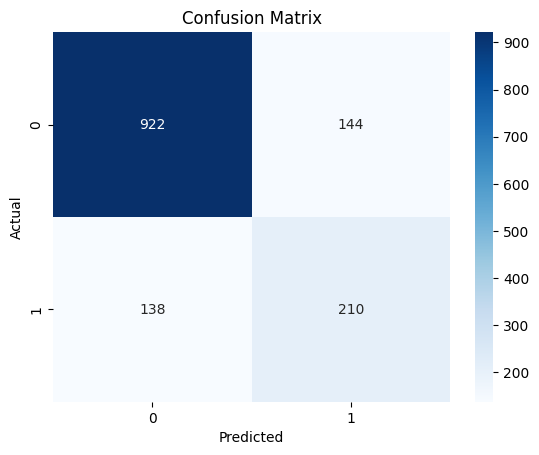

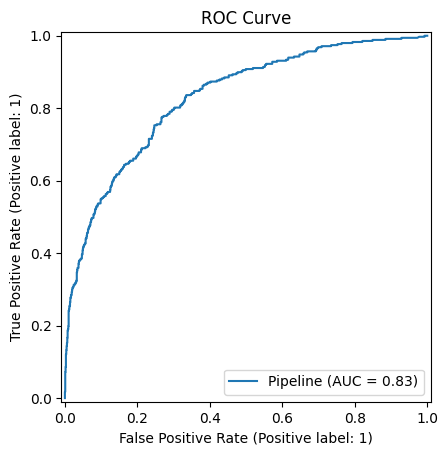

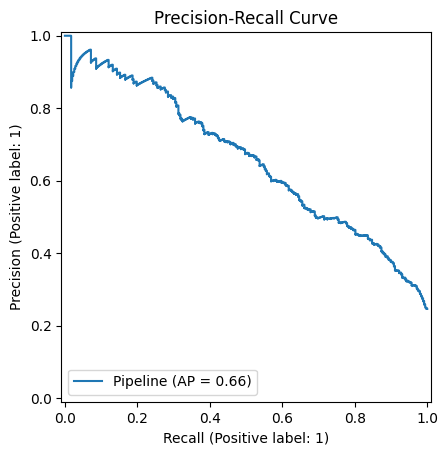

In [ ]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# ROC Curve
RocCurveDisplay.from_estimator(best_model, X_test, y_test)
plt.title("ROC Curve")
plt.show()

# Precision-Recall Curve
PrecisionRecallDisplay.from_estimator(best_model, X_test, y_test)
plt.title("Precision-Recall Curve")
plt.show()

/tmp/ipython-input-3723880477.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances, y=importances.index, palette='viridis')


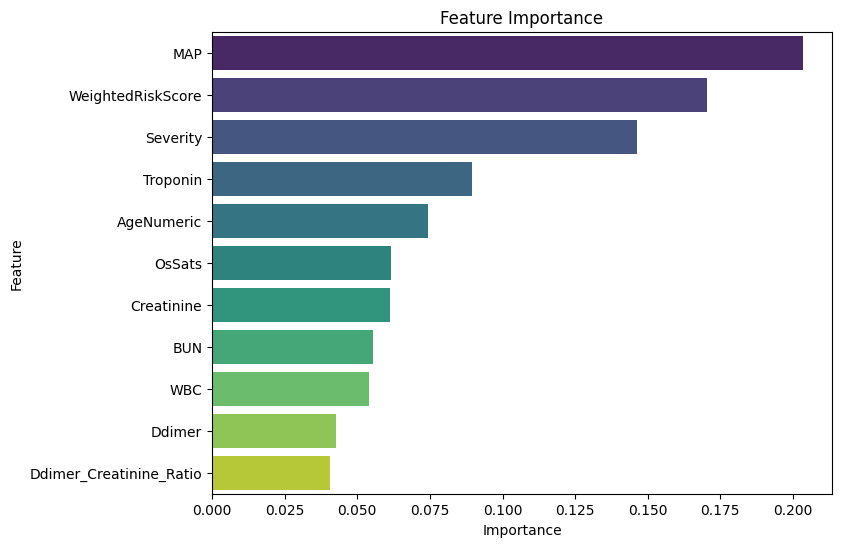


Feature Importances:
 MAP                        0.203274
WeightedRiskScore          0.170532
Severity                   0.146447
Troponin                   0.089527
AgeNumeric                 0.074184
OsSats                     0.061719
Creatinine                 0.061402
BUN                        0.055440
WBC                        0.053942
Ddimer                     0.042831
Ddimer_Creatinine_Ratio    0.040701
dtype: float64
Cross-Validation AUC: 0.826 ± 0.088


In [ ]:
# ================== 4. Feature Importance ==================
# استخراج ویژگی‌ها بعد از مرحله scaling
rf = best_model.named_steps['model']
importances = pd.Series(rf.feature_importances_, index=features).sort_values(ascending=False)

plt.figure(figsize=(8, 6))
sns.barplot(x=importances, y=importances.index, palette='viridis')
plt.title("Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

print("\nFeature Importances:\n", importances)

# ================== 5. Cross-validation AUC ==================
from sklearn.model_selection import cross_val_score
cv_auc = cross_val_score(best_model, X, y, cv=5, scoring='roc_auc')
print(f"Cross-Validation AUC: {cv_auc.mean():.3f} ± {cv_auc.std():.3f}")

In [ ]:
!pip install pandas numpy scikit-learn lightgbm optuna imbalanced-learn matplotlib seaborn
!pip install shap


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 395.9/395.9 kB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 247.0/247.0 kB 16.0 MB/s eta 0:00:00


[I 2025-08-15 19:23:13,712] A new study created in memory with name: lgbm_auroc


  0%|          | 0/40 [00:00<?, ?it/s]

[I 2025-08-15 19:23:41,478] Trial 0 finished with value: 0.814410618048389 and parameters: {'learning_rate': 0.0011132019396002885, 'n_estimators': 942, 'num_leaves': 234, 'max_depth': 17, 'min_data_in_leaf': 53, 'feature_fraction': 0.9817248392482666, 'bagging_fraction': 0.44489093861672036, 'bagging_freq': 5, 'lambda_l1': 0.004067950861524471, 'lambda_l2': 2.392259334442764e-06}. Best is trial 0 with value: 0.814410618048389.
[I 2025-08-15 19:23:54,725] Trial 1 finished with value: 0.8116529067767457 and parameters: {'learning_rate': 0.001857508188667858, 'n_estimators': 671, 'num_leaves': 201, 'max_depth': 12, 'min_data_in_leaf': 73, 'feature_fraction': 0.834287324026235, 'bagging_fraction': 0.8508005293386939, 'bagging_freq': 4, 'lambda_l1': 1.6940111148131726e-08, 'lambda_l2': 0.8948360330977444}. Best is trial 0 with value: 0.814410618048389.
[I 2025-08-15 19:24:12,407] Trial 2 finished with value: 0.8178419905974085 and parameters: {'learning_rate': 0.004138937140262803, 'n_esti

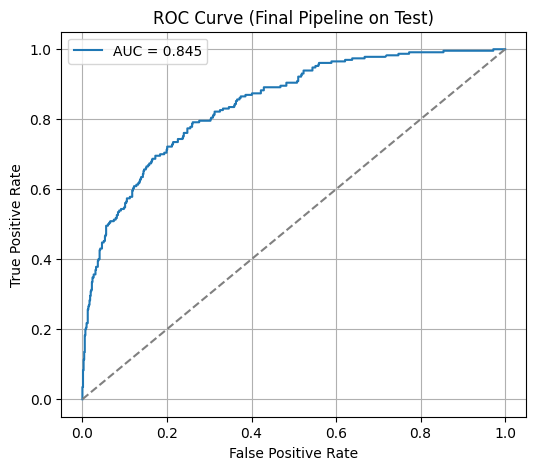

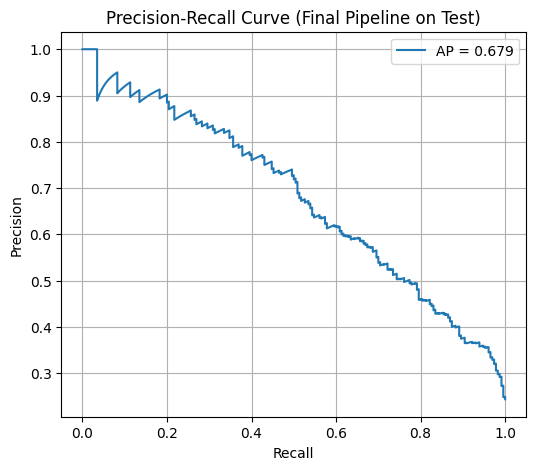

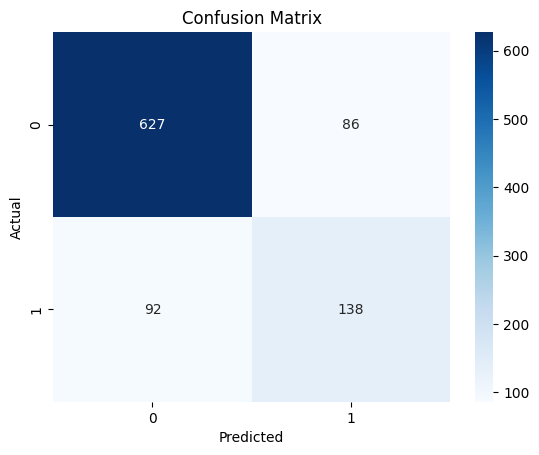

[LightGBM] [Warning] min_data_in_leaf is set=22, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=22
[LightGBM] [Warning] bagging_freq is set=7, subsample_freq=0 will be ignored. Current value: bagging_freq=7
[LightGBM] [Warning] feature_fraction is set=0.43673346661239076, colsample_bytree=1.0 will be ignored. Current value: feature_fraction=0.43673346661239076
[LightGBM] [Warning] lambda_l2 is set=7.259381163369674e-07, reg_lambda=0.0 will be ignored. Current value: lambda_l2=7.259381163369674e-07
[LightGBM] [Warning] lambda_l1 is set=0.14122960856709196, reg_alpha=0.0 will be ignored. Current value: lambda_l1=0.14122960856709196
[LightGBM] [Warning] bagging_fraction is set=0.6003344273104368, subsample=1.0 will be ignored. Current value: bagging_fraction=0.6003344273104368
[LightGBM] [Warning] min_data_in_leaf is set=22, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=22
[LightGBM] [Warning] bagging_freq is set=7, subsample_freq=0 will be i

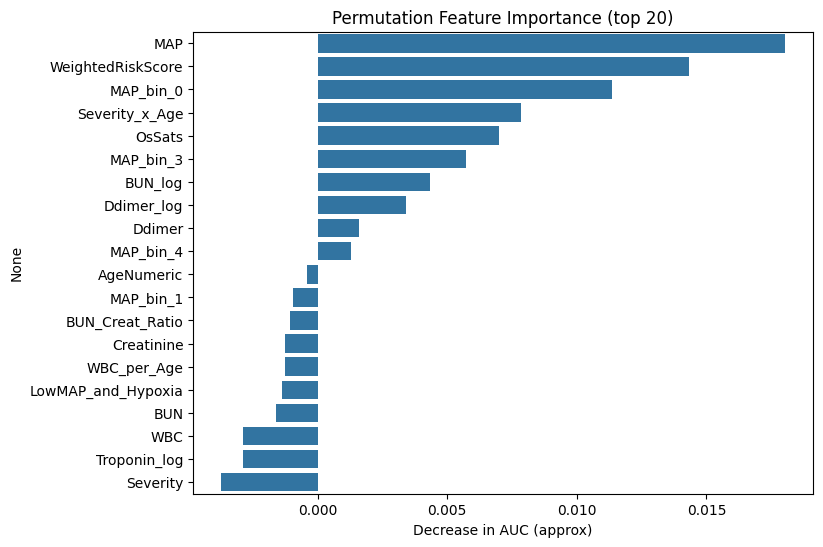


Top features:
 MAP                   0.018028
WeightedRiskScore     0.014316
MAP_bin_0             0.011347
Severity_x_Age        0.007847
OsSats                0.006999
MAP_bin_3             0.005726
BUN_log               0.004348
Ddimer_log            0.003393
Ddimer                0.001591
MAP_bin_4             0.001273
AgeNumeric           -0.000424
MAP_bin_1            -0.000954
BUN_Creat_Ratio      -0.001060
Creatinine           -0.001273
WBC_per_Age          -0.001273
LowMAP_and_Hypoxia   -0.001379
BUN                  -0.001591
WBC                  -0.002863
Troponin_log         -0.002863
Severity             -0.003712
dtype: float64


In [ ]:
# advanced_pipeline_optuna_lgbm.py
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, KBinsDiscretizer, PowerTransformer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    roc_auc_score, roc_curve, precision_recall_curve,
    average_precision_score, classification_report, confusion_matrix
)
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.inspection import permutation_importance

import lightgbm as lgb
import optuna

from imblearn.combine import SMOTETomek
from imblearn.pipeline import Pipeline as ImbPipeline

# ===================== 0. Helpers =====================
def plot_roc_pr(y_test, y_proba, title_suffix=""):
    # ROC
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc = roc_auc_score(y_test, y_proba)
    plt.figure(figsize=(6,5))
    plt.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
    plt.plot([0,1],[0,1],'--', color='grey')
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve " + title_suffix)
    plt.legend()
    plt.grid(True)
    plt.show()

    # Precision-Recall
    precision, recall, _ = precision_recall_curve(y_test, y_proba)
    ap = average_precision_score(y_test, y_proba)
    plt.figure(figsize=(6,5))
    plt.plot(recall, precision, label=f"AP = {ap:.3f}")
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title("Precision-Recall Curve " + title_suffix)
    plt.legend()
    plt.grid(True)
    plt.show()

def plot_confusion(y_true, y_pred, labels=[0,1]):
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title("Confusion Matrix")
    plt.show()

# ===================== 1. Load data & basic cleaning =====================
try:
    df = pd.read_excel("main.xlsx")
except FileNotFoundError:
    raise SystemExit("خطا: فایل 'main.xlsx' پیدا نشد. آن را در مسیر جاری قرار دهید.")

# Map Age (تبدیل دسته‌ای Age به عدد)
df['AgeNumeric'] = df['Age'].map({'>80': 85, '>70': 75, '>60': 65, '0-60': 45})
# اگر مقدار دیگری هست سعی کنید مناسب map اضافه کنید
df = df.dropna(subset=['AgeNumeric', 'Death'])

# ===================== 2. Feature Engineering =====================
# مثال‌های پیشنهادی - بسته به داده شما ممکن است لازم به اصلاح باشد
df['WeightedRiskScore'] = (
    0.3 * df.get('MAP < 70', 0) + 0.2 * df.get('Severity', 0) +
    0.1 * df.get('CrtnScore', 0) + 0.1 * df.get('Troponin > 0.1', 0) +
    0.09 * df.get('O2 Sat < 94', 0) + 0.08 * df.get('BUN > 30', 0) +
    0.08 * df.get('D-Dimer > 3', 0)
)

# نسبت‌ها و تعامل‌ها
df['Ddimer_Creatinine_Ratio'] = df['Ddimer'] / (df['Creatinine'] + 1e-6)
df['BUN_Creat_Ratio'] = df['BUN'] / (df['Creatinine'] + 1e-6)
df['WBC_per_Age'] = df['WBC'] / (df['AgeNumeric'] + 1e-6)
df['Severity_x_Age'] = df['Severity'] * df['AgeNumeric']
df['LowMAP_and_Hypoxia'] = (df['MAP < 70']>0).astype(int) * (df['O2 Sat < 94']>0).astype(int)

# Transform skewed numeric features (log1p)
for col in ['Ddimer', 'Creatinine', 'BUN', 'Troponin', 'WBC']:
    if col in df.columns:
        df[col + '_log'] = np.log1p(df[col].astype(float).clip(lower=0))

# optional: binning (مثال برای MAP)
if 'MAP' in df.columns:
    kb = KBinsDiscretizer(n_bins=5, encode='onehot-dense', strategy='quantile')
    try:
        map_bins = kb.fit_transform(df[['MAP']].fillna(df['MAP'].median()))
        # اضافه کردن ستون‌های باینری باندها به df با نام MAP_bin_0..4
        for i in range(map_bins.shape[1]):
            df[f'MAP_bin_{i}'] = map_bins[:, i]
    except Exception:
        pass

# ===================== 3. Define features & target =====================
# لیست اولیهٔ ویژگی‌ها — ممکن است بسته به ستون‌های فایل شما تغییر کند
features = [
    'MAP', 'MAP_bin_0','MAP_bin_1','MAP_bin_2','MAP_bin_3','MAP_bin_4' if 'MAP_bin_4' in df.columns else None,
    'Severity', 'Creatinine', 'Creatinine_log', 'WBC', 'WBC_log',
    'OsSats', 'BUN', 'BUN_log', 'Ddimer', 'Ddimer_log', 'Troponin', 'Troponin_log',
    'AgeNumeric', 'WeightedRiskScore', 'Ddimer_Creatinine_Ratio', 'BUN_Creat_Ratio',
    'WBC_per_Age', 'Severity_x_Age', 'LowMAP_and_Hypoxia'
]
# پاکسازی None‌ها و ستون‌هایی که وجود ندارند
features = [f for f in features if f and f in df.columns]

target = 'Death'
df = df.dropna(subset=features + [target])
X = df[features].copy()
y = df[target].astype(int)

# ===================== 4. Train-test split (final held-out test) =====================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# ===================== 5. Pipeline: scaler + SMOTETomek + model =====================
scaler = StandardScaler()

smote_tomek = SMOTETomek(random_state=42)

# We'll tune LightGBM params via Optuna
def objective(trial):
    # hyperparams for LGBM
    param = {
        'objective': 'binary',
        'metric': 'auc',
        'verbosity': -1,
        'boosting_type': 'gbdt',
        'learning_rate': trial.suggest_loguniform('learning_rate', 1e-3, 0.2),
        'n_estimators': trial.suggest_int('n_estimators', 100, 1000),
        'num_leaves': trial.suggest_int('num_leaves', 16, 256),
        'max_depth': trial.suggest_int('max_depth', 3, 20),
        'min_data_in_leaf': trial.suggest_int('min_data_in_leaf', 5, 100),
        'feature_fraction': trial.suggest_uniform('feature_fraction', 0.4, 1.0),
        'bagging_fraction': trial.suggest_uniform('bagging_fraction', 0.4, 1.0),
        'bagging_freq': trial.suggest_int('bagging_freq', 0, 10),
        'lambda_l1': trial.suggest_loguniform('lambda_l1', 1e-8, 10.0),
        'lambda_l2': trial.suggest_loguniform('lambda_l2', 1e-8, 10.0),
    }

    # Imbalanced pipeline for CV inside Optuna
    model = lgb.LGBMClassifier(**param, random_state=42, n_jobs=-1)

    imb_pipeline = ImbPipeline([
        ('scaler', scaler),
        ('smote_tomek', smote_tomek),
        ('model', model)
    ])

    # inner CV
    cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
    scores = cross_val_score(imb_pipeline, X_train, y_train, cv=cv, scoring='roc_auc', n_jobs=-1)
    return scores.mean()

# Optuna study
study = optuna.create_study(direction='maximize', study_name="lgbm_auroc")
study.optimize(objective, n_trials=40, show_progress_bar=True)  # n_trials را می‌توان افزایش داد

print("Best trial:")
print(study.best_trial.params)

# ===================== 6. Build final stacking model using best LGBM + other base learners =====================
best_params = study.best_trial.params
best_lgb = lgb.LGBMClassifier(**best_params, random_state=42, n_jobs=-1)

# سایر مدل‌های پایه برای stacking (سبک و قابل اطمینان)
rf = RandomForestClassifier(n_estimators=300, max_depth=12, random_state=42, n_jobs=-1)
lr = LogisticRegression(max_iter=1000, class_weight='balanced')

# Stacking: پایه‌ها lgb و rf و lr، نهایی یک lgb سبک
estimators = [
    ('lr', lr),
    ('rf', rf),
    ('lgb_base', best_lgb)
]
final_estimator = lgb.LGBMClassifier(**{**best_params, 'n_estimators': int(best_params.get('n_estimators',200)*0.6)}, random_state=42)

stack = StackingClassifier(
    estimators=estimators,
    final_estimator=final_estimator,
    cv=5,
    n_jobs=-1,
    passthrough=False
)

# Pipeline با scaler و SMOTETomek و سپس stacking
final_pipeline = ImbPipeline([
    ('scaler', scaler),
    ('smote_tomek', smote_tomek),
    ('stack', stack)
])

# ===================== 7. Nested CV (outer) برای ارزیابی واقعی =====================
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
nested_scores = cross_val_score(final_pipeline, X, y, cv=outer_cv, scoring='roc_auc', n_jobs=-1)
print(f"Nested CV AUC: {nested_scores.mean():.4f} ± {nested_scores.std():.4f}")

# ===================== 8. Fit final pipeline on train set and evaluate on held-out test =====================
final_pipeline.fit(X_train, y_train)
y_test_proba = final_pipeline.predict_proba(X_test)[:, 1]
y_test_pred = final_pipeline.predict(X_test)

print("Test AUC:", roc_auc_score(y_test, y_test_proba))
print("\nClassification report on TEST:\n", classification_report(y_test, y_test_pred, digits=3))

plot_roc_pr(y_test, y_test_proba, title_suffix="(Final Pipeline on Test)")
plot_confusion(y_test, y_test_pred)

# ===================== 9. Feature importance via permutation importance =====================
# برای محاسبهٔ permutation importance نیاز است مدل ثابت باشد؛
# استفاده از X_test و y_test برای سنجش تأثیر هر ویژگی
result = permutation_importance(final_pipeline, X_test, y_test, n_repeats=10, random_state=42, n_jobs=-1)
perm_importances = pd.Series(result.importances_mean, index=X_test.columns).sort_values(ascending=False)

plt.figure(figsize=(8,6))
sns.barplot(x=perm_importances.values[:20], y=perm_importances.index[:20])
plt.title("Permutation Feature Importance (top 20)")
plt.xlabel("Decrease in AUC (approx)")
plt.show()

print("\nTop features:\n", perm_importances.head(20))

# ===================== 10. Save model (اختیاری) =====================
# import joblib
# joblib.dump(final_pipeline, "final_stacked_pipeline.joblib")
# print("Model saved to final_stacked_pipeline.joblib")
